In [1]:
from src.data import DataLoader
from src.timescales import Timescales

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
dataset = 'HCP-YA'
data_loader = DataLoader(dataset=dataset)

Initialized DataLoader for dataset: HCP-YA
Base directory: /mnt/storage_ssd_raid/research_data/HCP_YA
Raw data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/HCP_1200
Derivatives data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/derivatives
Output directory: /home/lindenmp/intrinsic_neural_timescales
Loaded behavioral data: 1206 subjects


In [3]:
# subject_ids = data_loader.df_behavior.index.astype(str).tolist()[:20]  # First 10 subjects
# subject_ids = ['100206', '100307', '100408', '100610', '101006', '101107', '101309', '101915', 
#                '102008', '102109', '102311', '102513', '102614', '102715', '102816', '103111', 
#                '103212', '103414', '103515', '103818']
subject_ids = ['102816', ]
            #    '100610', '102311', '102816', '104416', '105923', '108323', '109123', '111514', '114823', '115017']
            #    '115825', '116726', '118225', '125525', '126426', '128935', '130114', '130518', '131217', '131722']
subject_ids

['102816']

In [4]:
# Register 3T REST scans
rest_scans = data_loader.register_3t_rest_scans(
    subject_ids=subject_ids,
    atlas='Schaefer4007',
    sessions=[1, 2],
    phase_encodings=['LR', 'RL']
)

# Load the data
rest_data = data_loader.load_batch(
    modalities=['MRI_3T'],
    conditions=['rest'],
    verbose=True
)

print(f"Loaded {len(rest_data)} scans")
# data_loader.clear_cache()

Loading 4 scans...
  [1/4] 102816 rfMRIREST1LR

Loaded: 4/4 scans
Loaded 4 scans


In [5]:
# =========================
meg_scans = data_loader.register_meg_scans(
    subject_ids=subject_ids,
    atlas='Schaefer4007',
    rest_runs=[3, 4, 5],
    wm_runs=[6, 7]
)

meg_data = data_loader.load_batch(
    modalities=['MEG'],
    nuisance_regression=False,
    verbose=True
)

Loading 5 scans...
  [1/5] 102816 3-Restin

Loaded: 5/5 scans


<Axes: >

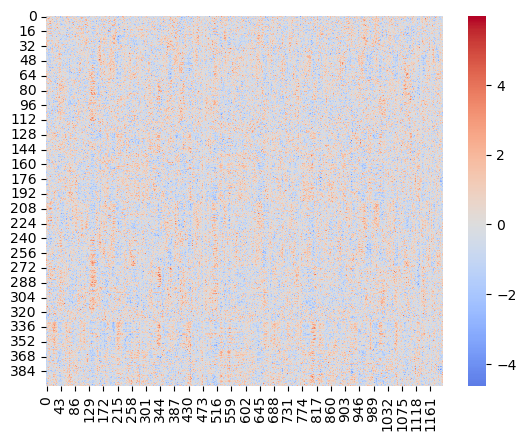

In [6]:
sns.heatmap(rest_data['102816_MRI_3T_rfMRIREST1LR_Schaefer4007'], cmap='coolwarm', center=0)
# sns.heatmap(meg_data['102816_MEG_3-Restin_Schaefer4007'], cmap='coolwarm', center=0)

In [7]:
data_loader.summary()


Dataset: HCP-YA
Base directory: /mnt/storage_ssd_raid/research_data/HCP_YA
Output directory: /home/lindenmp/intrinsic_neural_timescales
Registered scans: 9

Scans by modality:
modality
MEG       5
MRI_3T    4
Name: count, dtype: int64

Scans by condition:
condition
rest    7
task    2
Name: count, dtype: int64

Behavioral data: (1206, 584)

Cache: 9 scans, 1882.1 MB



In [8]:
timescales_processor = Timescales(dataset=dataset, timeseries_data=meg_data, modality='MEG')

Initialized DataLoader for dataset: HCP-YA
Base directory: /mnt/storage_ssd_raid/research_data/HCP_YA
Raw data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/HCP_1200
Derivatives data directory: /mnt/storage_ssd_raid/research_data/HCP_YA/derivatives
Output directory: /home/lindenmp/intrinsic_neural_timescales
Loaded behavioral data: 1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Modality: MEG
	TR: 0.0019660657059158916


In [9]:
timescales_processor.compute_autocorrelation_function(use_fft=True, freq_window=None)
autocorr = timescales_processor.autocorr

100%|██████████| 5/5 [00:13<00:00,  2.73s/it]


102816_MEG_3-Restin_Schaefer4007 (400, 186760)
102816_MEG_4-Restin_Schaefer4007 (400, 189044)
102816_MEG_5-Restin_Schaefer4007 (400, 211323)
102816_MEG_6-Wrkmem_Schaefer4007 (400, 317695)
102816_MEG_7-Wrkmem_Schaefer4007 (400, 319015)


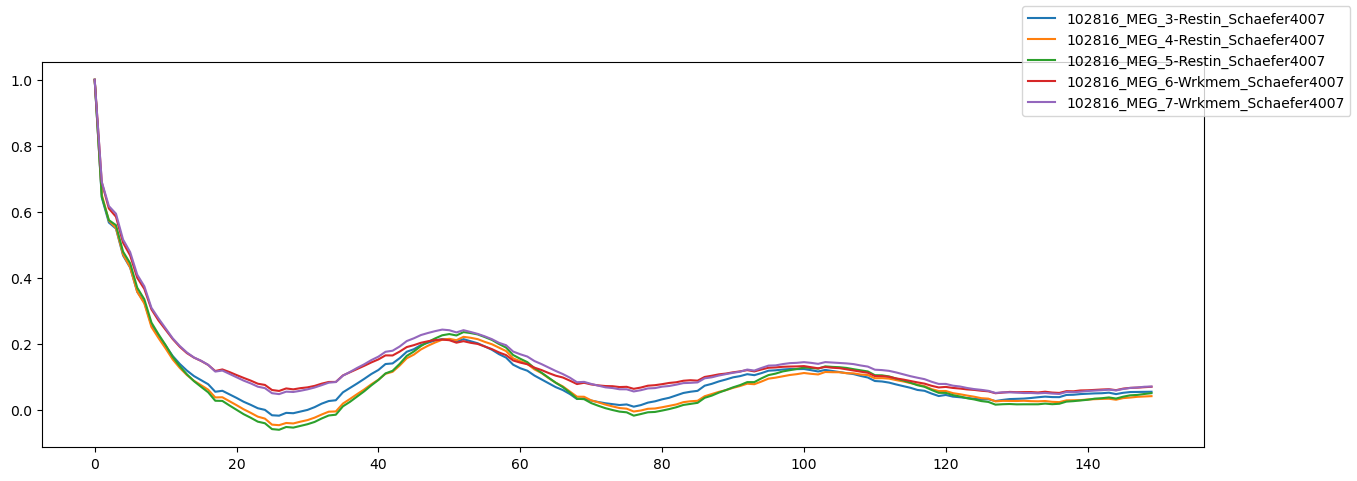

In [10]:
fig, axes = plt.subplots(1, 1, figsize=(15, 5))
for scan in autocorr.keys():
    print(scan, autocorr[scan].shape)
    plt.plot(autocorr[scan].mean(axis=0)[:150], label=scan)
fig.legend()